# Capítulo 11 · Probabilidade: caderno complementar
*Ciência de Dados e Inteligência Artificial em Saúde, Volume 1*

> **Este caderno acompanha o capítulo do livro; não o reproduz.** Definições, deduções e explicações estão no livro. Aqui você executa os cálculos do caso e confere os números. Todos os dados são **sintéticos** e os valores têm apenas finalidade didática; não possuem correlação com o mundo real.

A **Parte A** percorre o caso do capítulo, o registro de partos de uma maternidade pública, pelas seis perguntas do comitê. A **Parte B** traz o código e o resultado de cada um dos doze exercícios do capítulo (os enunciados estão no livro). Execute as células em ordem. As saídas do código usam ponto decimal.

## Parte A. O caso

**Dados.** `data/deliveries.csv`: 5.000 linhas, uma por parto, e quatro colunas: `delivery_id`, `cesarean`, `hemorrhage`, `infection` (sim/não, escritos `yes`/`no`). As seis seções a seguir seguem as perguntas do comitê, na ordem do capítulo.

As cinco primeiras linhas do registro:

In [1]:
import pandas as pd

register = pd.read_csv("data/deliveries.csv")
rows, columns = register.shape
print(f"O registro tem {rows} linhas (uma por parto) e {columns} colunas.")
register.head()

O registro tem 5000 linhas (uma por parto) e 4 colunas.


,delivery_id,cesarean,hemorrhage,infection
0,D0001,no,no,no
1,D0002,no,no,no
2,D0003,yes,no,no
3,D0004,no,no,no
4,D0005,yes,no,no


### P1. Que fração dos partos foi cesárea e que fração teve hemorragia?

Partos no registro: 5000
cesarean
no     3687
yes    1313 

cesarean     1313 de 5000 partos = 26.26%
hemorrhage    290 de 5000 partos = 5.80%

 linhas lidas  cesáreas até agora  fração
           10                   5  0.5000
           50                  19  0.3800
          100                  27  0.2700
          500                 123  0.2460
         1000                 246  0.2460
         5000                1313  0.2626


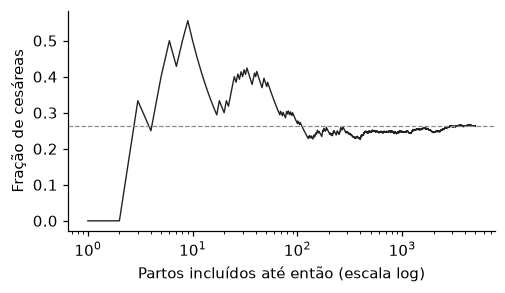

In [2]:
import pandas as pd

df = pd.read_csv("data/deliveries.csv")

# 1. Pegar todas as linhas: cada linha é um parto
n = len(df)
print(f"Partos no registro: {n}")

# 2. Em cada linha, olhar a coluna: está "yes"?
C = df["cesarean"] == "yes"
H = df["hemorrhage"] == "yes"
I = df["infection"] == "yes"
print(df["cesarean"].value_counts().to_string(), "\n")

# 3. Contar as linhas "yes" e dividir por todas as linhas
for name, event in (("cesarean", C), ("hemorrhage", H)):
    count = int(event.sum())
    print(f"{name:<11} {count:>5} de {n} partos = {count / n:.2%}")

# 4. Ler o registro em ordem: a fração de cesáreas se estabiliza?
running = C.cumsum() / range(1, n + 1)   # cesáreas até agora / linhas lidas até agora
checkpoints = [10, 50, 100, 500, 1000, 5000]
print()
print(pd.DataFrame({"linhas lidas": checkpoints,
                    "cesáreas até agora": [int(C.iloc[:k].sum()) for k in checkpoints],
                    "fração": [round(running.iloc[k - 1], 4) for k in checkpoints]}).to_string(index=False))

import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(range(1, n + 1), running, color="#222222", linewidth=.9)
ax.axhline(C.mean(), color="#8a8a8a", linewidth=.8, linestyle="--")
ax.set(xscale="log", xlabel="Partos incluídos até então (escala log)", ylabel="Fração de cesáreas")
plt.show()

### P2. Quantas mães tiveram hemorragia ou infecção?

In [3]:
# 1. Cruzar as duas colunas: cada parto cai em exatamente uma de quatro células
print(pd.crosstab(df["hemorrhage"], df["infection"], margins=True, margins_name="Total"), "\n")

# 2. Somar os dois grupos e corrigir as mães contadas duas vezes
hemorrhage, infection, both = int(H.sum()), int(I.sum()), int((H & I).sum())
print(f"Hemorragia:               {hemorrhage:>4}")
print(f"Infecção:                 {infection:>4}")
print(f"Somando as duas:          {hemorrhage + infection:>4}   (as {both} mães com ambas foram contadas duas vezes)")
print(f"Ambas:                    {both:>4}")
print(f"Hemorragia ou infecção:   {hemorrhage + infection - both:>4}   = {hemorrhage} + {infection} - {both}\n")

# 3. Conferir contando diretamente e contar as mães sem nenhuma das duas
either = H | I                           # True quando a linha tem ao menos uma das duas
print(f"Contando direto:  {int(either.sum())} de {n} = {either.mean():.2%}")
print(f"Sem nenhuma:      {int((~either).sum())} de {n} = {(~either).mean():.2%}")

infection     no  yes  Total
hemorrhage                  
no          4599  111   4710
yes          271   19    290
Total       4870  130   5000 

Hemorragia:                290
Infecção:                  130
Somando as duas:           420   (as 19 mães com ambas foram contadas duas vezes)
Ambas:                      19
Hemorragia ou infecção:    401   = 290 + 130 - 19

Contando direto:  401 de 5000 = 8.02%
Sem nenhuma:      4599 de 5000 = 91.98%


### P3. A infecção é mais frequente após cesárea?

In [4]:
for group in (C, ~C):
    print(int(group.sum()), int((group & I).sum()),
          f"{I[group].mean():.4f}")
print(f"{(C & I).mean():.4f}", f"{I.mean():.4f}")

1313 87 0.0663
3687 43 0.0117
0.0174 0.0260


### P4. Hemorragia e infecção vêm juntas ou de modo independente?

In [5]:
print(f"{H.mean() * I.mean():.6f}",
      f"{(H & I).mean():.4f}")
print(f"{I[H].mean():.4f}", f"{I[~H].mean():.4f}")
print(int(C.sum()), int((C & H).sum()),
      int((C & H & I).sum()))
chain = C.mean() * H[C].mean() * I[C & H].mean()
print(f"{H.mean() * I[H].mean():.4f}")
print(f"{chain:.4f}", f"{(C & H & I).mean():.4f}")

0.001508 0.0038
0.0655 0.0236
1313 95 14
0.0038
0.0028 0.0028


### P5. Entre as mães com infecção, que fração teve cesárea?

In [6]:
p_i = I[C].mean() * C.mean() + I[~C].mean() * (~C).mean()
p_c_given_i = I[C].mean() * C.mean() / p_i
print(f"{p_i:.4f}")
print(int((C & I).sum()), int(I.sum()))
print(f"{p_c_given_i:.4f}", f"{C[I].mean():.4f}")
print(f"{100 * p_c_given_i:.1f}%")

0.0260
87 130
0.6692 0.6692
66.9%


### P6. De quantas maneiras se escolhem 20 prontuários e qual a chance de a amostra incluir uma infecção?

In [7]:
from math import comb, factorial, perm

N, K = n, int(I.sum())
def p_at_least_one(m):
    return 1 - comb(N - K, m) / comb(N, m)

print(comb(N, 20), len(str(comb(N, 20))))
print(factorial(20), perm(20, 2))
print(f"{p_at_least_one(20):.4f}")
m = next(m for m in range(1, N + 1)
         if 10 * comb(N - K, m) <= comb(N, m))
for size in (m - 1, m):
    print(size, f"{p_at_least_one(size):.6f}")

37735558620382470911680923426535607627307325009655406000 56
2432902008176640000 380
0.4102
86 0.898259
87 0.900950


## Parte B. Soluções dos exercícios

### Exercício 1. Registros e descrições de eventos

In [8]:
import pandas as pd
from itertools import product

df = pd.read_csv("data/deliveries.csv")
n = len(df)
C = df["cesarean"] == "yes"
H = df["hemorrhage"] == "yes"
I = df["infection"] == "yes"
print(n, df["delivery_id"].nunique())
print(" ".join("".join(map(str, bits))
               for bits in product((0, 1), repeat=3)))

5000 5000
000 001 010 011 100 101 110 111


**Resultado:** 5.000 identificadores distintos; as oito descrições (C, H, I) estão listadas acima. Se são equiprováveis é discutido no livro.

### Exercício 2. Frações acumuladas e ordem

In [9]:
for k in (10, 50, 100, 500, 1000, 5000):
    print(k, f"{C.iloc[:k].mean():.4f}")
reverse = C.iloc[::-1]
print(f"{reverse.iloc[:100].mean():.4f}",
      f"{reverse.mean():.4f}")

10 0.5000
50 0.3800
100 0.2700
500 0.2460
1000 0.2460
5000 0.2626
0.2500 0.2626


**Resultado:** 0,5000, 0,3800, 0,2700, 0,2460, 0,2460, 0,2626; em ordem inversa, 0,2500 após 100 registros e 0,2626 após 5.000.

### Exercício 3. Contar a sobreposição uma vez

In [10]:
for group in (H & ~I, ~H & I, H & I, ~(H | I)):
    print(int(group.sum()), f"{group.mean():.4f}")
union = H.sum() + I.sum() - (H & I).sum()
print(int(union), f"{union / n:.4f}")
print(int((H | I).sum()), f"{1 - (H | I).mean():.4f}")

271 0.0542
111 0.0222
19 0.0038
4599 0.9198
401 0.0802
401 0.9198


**Resultado:** 271, 111, 19 e 4.599 partos; 401 com hemorragia ou infecção (0,0802); 0,9198 sem nenhuma.

### Exercício 4. Nomear o denominador

In [11]:
values = (I[C].mean(), (C & I).mean(), I.mean(),
          C[I].mean(), H[C].mean())
for letter, value in zip("abcde", values):
    print(letter, f"{value:.4f}")

a 0.0663
b 0.0174
c 0.0260
d 0.6692
e 0.0724


**Resultado:** (a) 0,0663 · (b) 0,0174 · (c) 0,0260 · (d) 0,6692 · (e) 0,0724. A classificação está no livro.

### Exercício 5. Comparar dentro dos tipos de parto

In [12]:
print(f"{I[C].mean():.4f}", f"{I[~C].mean():.4f}")
print(f"{I[C].mean() / I[~C].mean():.4f}")
for group in (C, ~C):
    print(int((H & group).sum()), int(group.sum()),
          f"{H[group].mean():.4f}")

0.0663 0.0117
5.6815
95 1313 0.0724
195 3687 0.0529


**Resultado:** Infecção 0,0663 vs 0,0117 (razão 5,6815); hemorragia 95/1.313 = 0,0724 vs 195/3.687 = 0,0529.

### Exercício 6. Dependência e sobreposição

In [13]:
print(f"{H.mean() * I.mean():.6f}",
      f"{(H & I).mean():.4f}")
print(f"{I[H].mean():.4f}", f"{I[~H].mean():.4f}")
print(int((H & I).sum()))

0.001508 0.0038
0.0655 0.0236
19


**Resultado:** Produto 0,001508 vs observado 0,0038; P(I|H) = 0,0655 vs P(I|não H) = 0,0236; 19 partos com ambos.

### Exercício 7. Dois caminhos para a mesma probabilidade conjunta

In [14]:
first = C.mean() * H[C].mean() * I[C & H].mean()
second = H.mean() * C[H].mean() * I[C & H].mean()
print(int(C.sum()), int(H.sum()), int((C & H).sum()),
      int((C & H & I).sum()))
print(f"{first:.4f}", f"{second:.4f}",
      f"{(C & H & I).mean():.4f}")

1313 290 95 14
0.0028 0.0028 0.0028


**Resultado:** 1.313 → 95 → 14; os dois caminhos dão 0,0028 = 14/5.000.

### Exercício 8. Probabilidade total e inversão

In [15]:
p_i = I[C].mean() * C.mean() + I[~C].mean() * (~C).mean()
bayes = I[C].mean() * C.mean() / p_i
print(f"{p_i:.4f}")
print(f"{bayes:.4f}", f"{C[I].mean():.4f}")
print(f"{(~C)[I].mean():.4f}")

0.0260
0.6692 0.6692
0.3308


**Resultado:** P(I) = 0,0260; P(C|I) = 0,6692 (87/130); parto vaginal entre as infecções 0,3308.

### Exercício 9. Ordens dos prontuários selecionados

In [16]:
from math import factorial, perm

print(factorial(20), perm(20, 2))
print(f"{factorial(19) / factorial(20):.4f}")
print(f"{factorial(18) / factorial(20):.6f}")

2432902008176640000 380
0.0500
0.002632


**Resultado:** 20! = 2.432.902.008.176.640.000; 20 × 19 = 380; probabilidades 0,0500 e 0,002632.

### Exercício 10. Uma amostra que inclui uma infecção

In [17]:
from math import comb

N, K = n, int(I.sum())
def p_at_least_one(m):
    return 1 - comb(N - K, m) / comb(N, m)

m = next(m for m in range(1, N + 1)
         if 10 * comb(N - K, m) <= comb(N, m))
for size in (20, m - 1, m):
    print(size, f"{p_at_least_one(size):.6f}")

20 0.410156
86 0.898259
87 0.900950


**Resultado:** 20 prontuários: 0,410156; 86: 0,898259; 87: 0,900950, a menor amostra com ao menos 90%.

### Exercício 11. Probabilidades marginais alternativas (alt.)

In [18]:
p_h, p_i = 0.02, 0.03
lower = max(p_h, p_i)
upper = min(1, p_h + p_i)
print(f"{lower:.4f}", f"{upper:.4f}")
print(f"{p_h + p_i - p_h * p_i:.4f}")

0.0300 0.0500
0.0494


**Resultado:** Probabilidade conjunta entre 0,0300 e 0,0500; se independentes, P(H ou I) = 0,0494.

### Exercício 12. Devolver prontuários entre sorteios (alt.)

In [19]:
from math import comb

N, K = n, int(I.sum())
with_replacement = 1 - ((N - K) / N) ** 20
without_replacement = 1 - comb(N - K, 20) / comb(N, 20)
print(f"{with_replacement:.6f}",
      f"{without_replacement:.6f}")
print(f"{without_replacement - with_replacement:.6f}")

0.409555 0.410156
0.000600


**Resultado:** Com reposição 0,409555; sem 0,410156; diferença 0,000600.

---
*Dados sintéticos (semente 11, `generate_data.py`). Valores apenas didáticos; nada aqui é recomendação clínica nem estimativa para uma unidade real.*